<a href="https://colab.research.google.com/github/aayushttimalsina/pytorch/blob/main/exercise_of_regression_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#exercise of the regression model

#Q1
#Create a straight line dataset using the linear regression formula (weight * X + bias).
#Set weight=0.3 and bias=0.9 there should be at least 100 datapoints total.
#Split the data into 80% training, 20% testing.
#Plot the training and testing data so it becomes visual.


In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

In [3]:
## lets create the data first

weight = 0.3
bias = 0.9

#create the steps and start and end point

start = 0
end = 1
step = 0.01

X = torch.arange(start, end, step).unsqueeze(1)
y = weight*X + bias

print(X.shape, y.shape)
len(X), len(y), X.dtype, y.dtype
X[:10], y[:10]

torch.Size([100, 1]) torch.Size([100, 1])


(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400],
         [0.0500],
         [0.0600],
         [0.0700],
         [0.0800],
         [0.0900]]),
 tensor([[0.9000],
         [0.9030],
         [0.9060],
         [0.9090],
         [0.9120],
         [0.9150],
         [0.9180],
         [0.9210],
         [0.9240],
         [0.9270]]))

In [4]:
### we will split the data

train_split = int(0.8 * len(X) )

X_train, y_train = X[: train_split  ], y[: train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test )

(80, 80, 20, 20)

In [5]:
##plot the data

def plot_predictions(train_data = X_train, train_labels = y_train,
                    test_data = X_test, test_labels = y_test, predictions = None):
   """
   plot training data and test data and compare the predictions
   """
   plt.figure(figsize=(10,7))

   plt.scatter(train_data, train_labels, c="b", s=4, label="training data")
   plt.scatter(test_data, test_labels, c="g", s=4, label="testing data")

   if predictions is not None:
       plt.scatter(test_data, predictions, c="r", s=4, label="predictions")

   plt.legend(prop={"size":14})


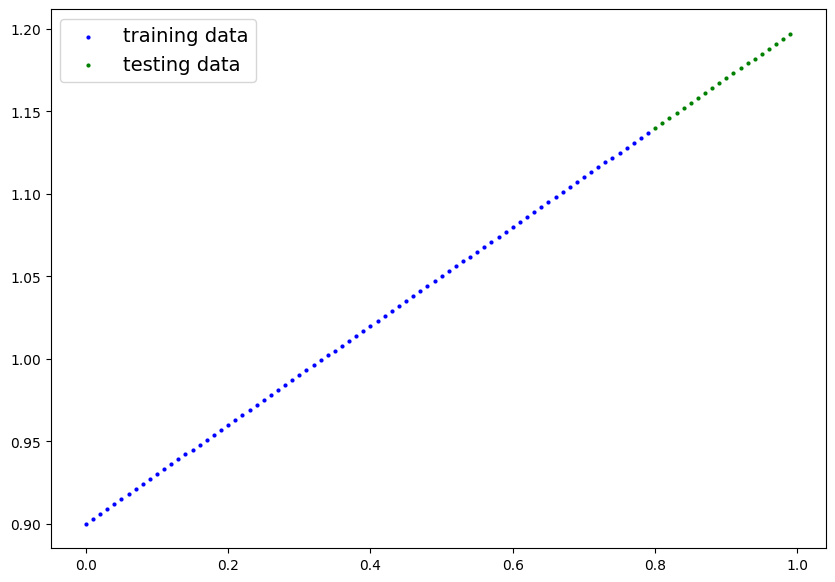

In [6]:
plot_predictions()

In [7]:
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(1, requires_grad=True, dtype= torch.float))
    self.bias = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float))

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.weights * x + self.bias


In [8]:
## we can also use nn.liner instead of nn.parameter

class LinearRegressionModel1(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear_layer = nn.Linear(in_features=1, out_features=1)

  def forward(self, x:torch.Tensor) -> torch.Tensor:
    return self.linear_layer(x)




In [9]:
#model_0 for the nn.linear

torch.manual_seed(42)
model_0 = LinearRegressionModel1()
model_0.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
             ('linear_layer.bias', tensor([0.8300]))])

In [10]:
## x_test for the nn.linear
with torch.inference_mode():
  y_preds1 = model_0(X_test)
y_preds1

tensor([[1.4416],
        [1.4493],
        [1.4569],
        [1.4646],
        [1.4722],
        [1.4799],
        [1.4875],
        [1.4952],
        [1.5028],
        [1.5104],
        [1.5181],
        [1.5257],
        [1.5334],
        [1.5410],
        [1.5487],
        [1.5563],
        [1.5640],
        [1.5716],
        [1.5793],
        [1.5869]])

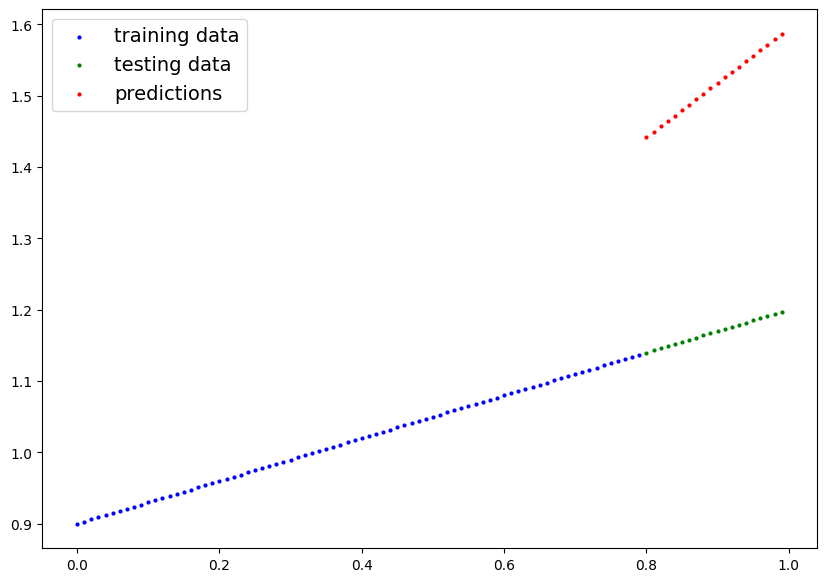

In [11]:
##predictions_plot for nn.linear

plot_predictions(predictions=y_preds1)

In [12]:
##model_1 for the nn.parameter

torch.manual_seed(42)
model_1 = LinearRegressionModel()
model_1.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [13]:
# x_test for nn.parameter

with torch.inference_mode():
 y_pred = model_1(X_test)
y_pred

tensor([[0.3982],
        [0.4015],
        [0.4049],
        [0.4083],
        [0.4116],
        [0.4150],
        [0.4184],
        [0.4217],
        [0.4251],
        [0.4285],
        [0.4318],
        [0.4352],
        [0.4386],
        [0.4419],
        [0.4453],
        [0.4487],
        [0.4520],
        [0.4554],
        [0.4588],
        [0.4621]])

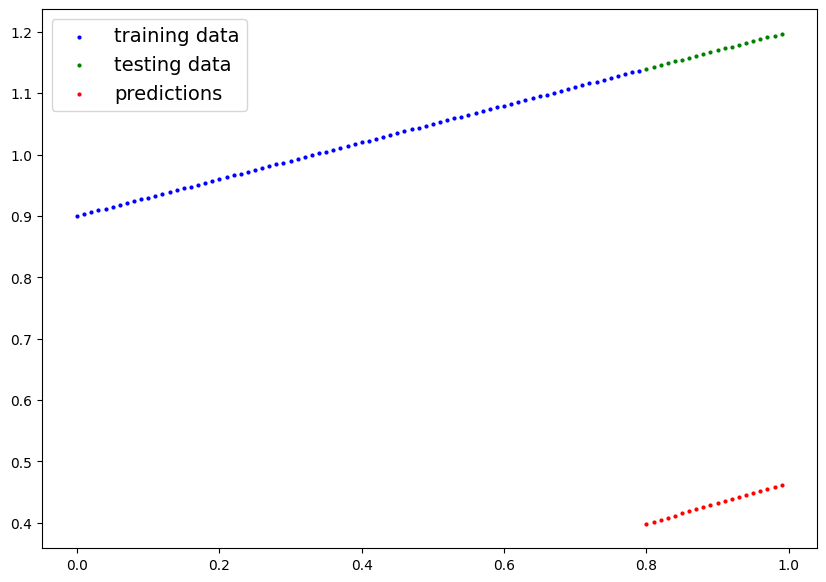

In [14]:
#predictions for nn.Parameter
plot_predictions(predictions=y_pred)

In [15]:
#Q3

#Create a loss function and optimizer using nn.L1Loss() and torch.optim.SGD(params, lr) respectively.
#Set the learning rate of the optimizer to be 0.01 and the parameters to optimize should be the model parameters from the model you created in 2.C
#Write a training loop to perform the appropriate training steps for 300 epochs.
#The training loop should test the model on the test dataset every 20 epochs.

In [50]:
# creating loss and the optimizer
loss_fn = nn.L1Loss()
optim1 = torch.optim.SGD(params= model_0.parameters(), lr = 0.01 )
optim2 = torch.optim.SGD(params= model_1.parameters(), lr = 0.01 )

In [62]:
## working on the model_1 for nn.parameters
## building a training loop
## for the teraining loop we have to follow the certrain steps
torch.manual_seed(42)
epoch_count = []
test_loss_values = []
train_loss_values = []

epochs = 300

##classify the epoches and run the range
## loop through the data
for epoch in range(epochs):

  #set the model in training mode
  model_1.train() #set this model to training model

  ##forward pass

  y_pred = model_1(X_train)

  #calculate the loss using the loss function

  loss = loss_fn(y_pred, y_train)

  #optimizer
  optim2.zero_grad()


  ## loss backward
  loss.backward()

  ##optimizer step step steppppp

  optim2.step()



  with torch.inference_mode():
    test_pred = model_1(X_test)
    test_loss = loss_fn(test_pred, y_test)

  if epoch % 20 == 0:

    epoch_count.append(epoch)
    test_loss_values.append(test_loss.item())
    train_loss_values.append(loss.item())

    print(f"epoch : {epoch} | train_loss : {loss.item()} | test_loss : {test_loss.item()}")


epoch : 0 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 20 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 40 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 60 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 80 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 100 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 120 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 140 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 160 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 180 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 200 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 220 | train_loss : 0.007858465425670147 | test_loss : 0.007045787759125233
epoch : 24

In [64]:
model_1.state_dict()

OrderedDict([('weights', tensor([0.3027])), ('bias', tensor([0.8911]))])

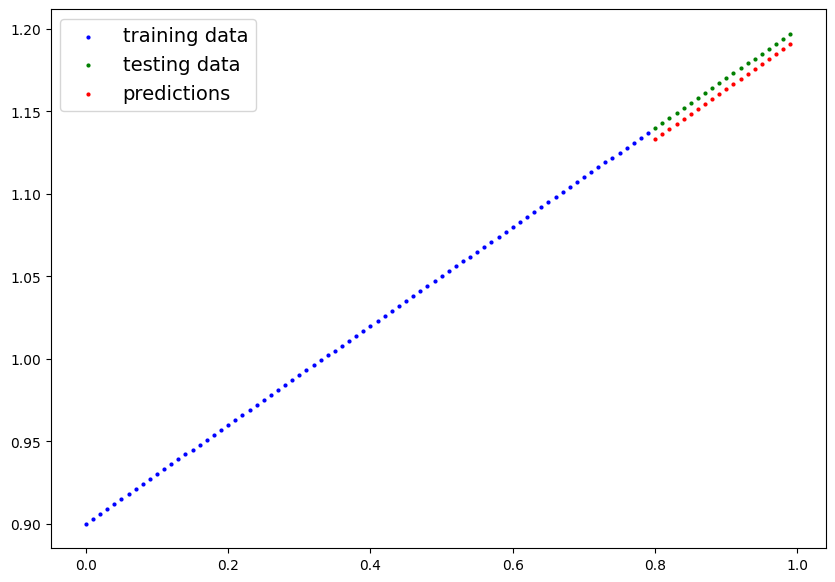

In [80]:
plot_predictions(predictions = test_pred)

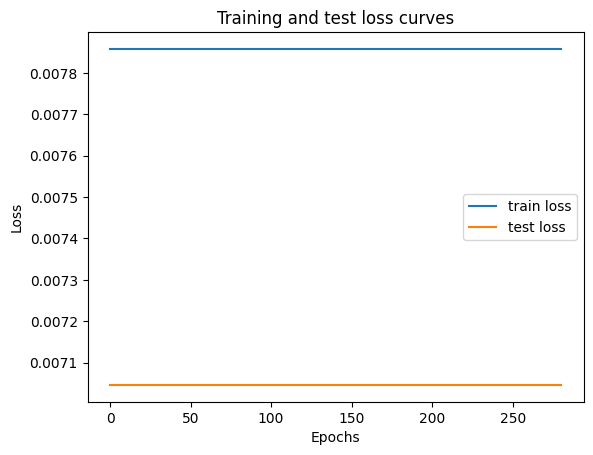

In [66]:
plt.plot(epoch_count, train_loss_values, label="train loss")
plt.plot(epoch_count, test_loss_values, label="test loss")

plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend()
plt.show()

In [54]:
### train loss and test loss are identical from epoch 10 so i checked before epoch 10 are they chaanging or not yes they are changing!!!!
## our model did good before the epoch 10
for epoch in range(6):

    model_1.train()

    y_pred = model_1(X_train)
    loss = loss_fn(y_pred, y_train)

    optim2.zero_grad()
    loss.backward()
    optim2.step()

    print(
        f"Epoch: {epoch} | "
        f"Loss: {loss.item():.8f} | "
        f"Weight: {model_1.weights.item():.6f} | "
        f"Bias: {model_1.bias.item():.6f}"
    )

Epoch: 0 | Loss: 0.00785847 | Weight: 0.306688 | Bias: 0.901060
Epoch: 1 | Loss: 0.00370178 | Weight: 0.302738 | Bias: 0.891060
Epoch: 2 | Loss: 0.00785847 | Weight: 0.306688 | Bias: 0.901060
Epoch: 3 | Loss: 0.00370178 | Weight: 0.302738 | Bias: 0.891060
Epoch: 4 | Loss: 0.00785847 | Weight: 0.306688 | Bias: 0.901060
Epoch: 5 | Loss: 0.00370178 | Weight: 0.302738 | Bias: 0.891060


In [75]:
### lets build the training loop for mode_0 with help of optim 1
torch.manual_seed(42)
epoches = 300

epoch_count_values = []
test_loss_values = []
train_loss_values = []

for epoch in range(epoches):

  model_0.train()

  y_pred = model_0(X_train)

  loss = loss_fn(y_pred, y_train)

  optim1.zero_grad()

  loss.backward()

  optim1.step()

  with torch.inference_mode():
    test_pred = model_0(X_test)
    test_loss = loss_fn(test_pred, y_test)

  if epoch % 20 == 0:

    epoch_count_values.append(epoch)
    test_loss_values.append(test_loss.item())
    train_loss_values.append(loss.item())

    print(f"epoch : {epoch} | train_loss : {loss.item()} | test_loss : {test_loss.item()}")










epoch : 0 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 20 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 40 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 60 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 80 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 100 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 120 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 140 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 160 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 180 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 200 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 220 | train_loss : 0.007878491654992104 | test_loss : 0.007064247038215399
epoch : 24

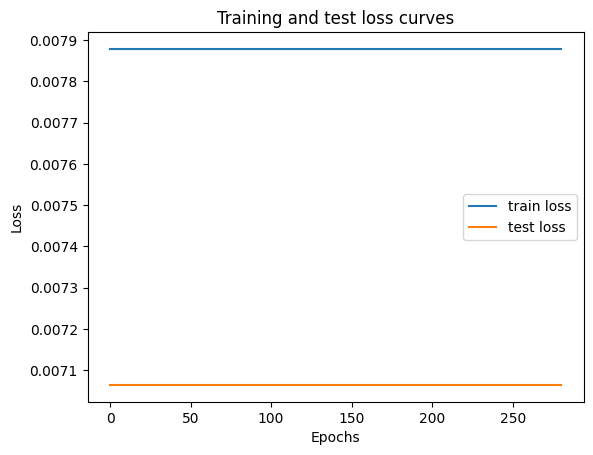

In [76]:

##model_0 plot using optim_1

plt.plot(epoch_count, train_loss_values, label="train loss")
plt.plot(epoch_count, test_loss_values, label="test loss")

plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend()
plt.show()

In [77]:
model_0.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.3028]])),
             ('linear_layer.bias', tensor([0.8910]))])

In [78]:
model_1.state_dict()

OrderedDict([('weights', tensor([0.3027])), ('bias', tensor([0.8911]))])

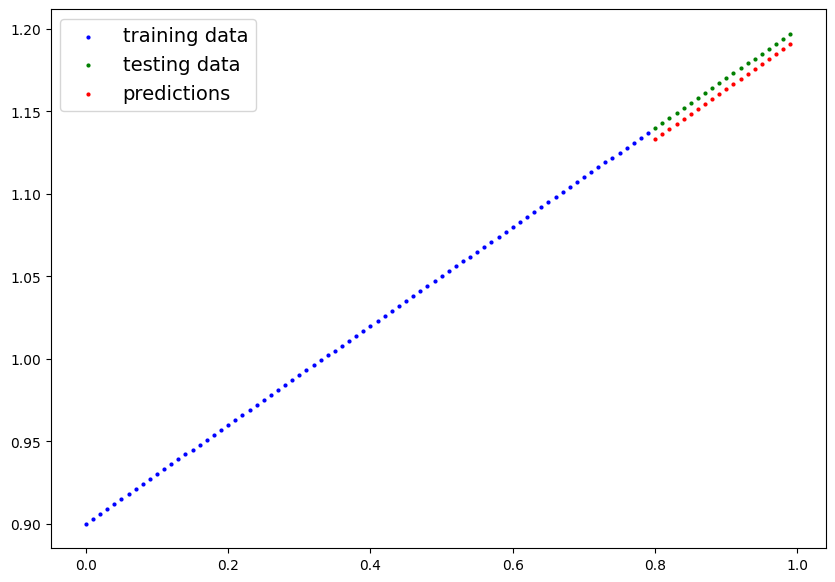

In [81]:
plot_predictions( predictions =  test_pred)

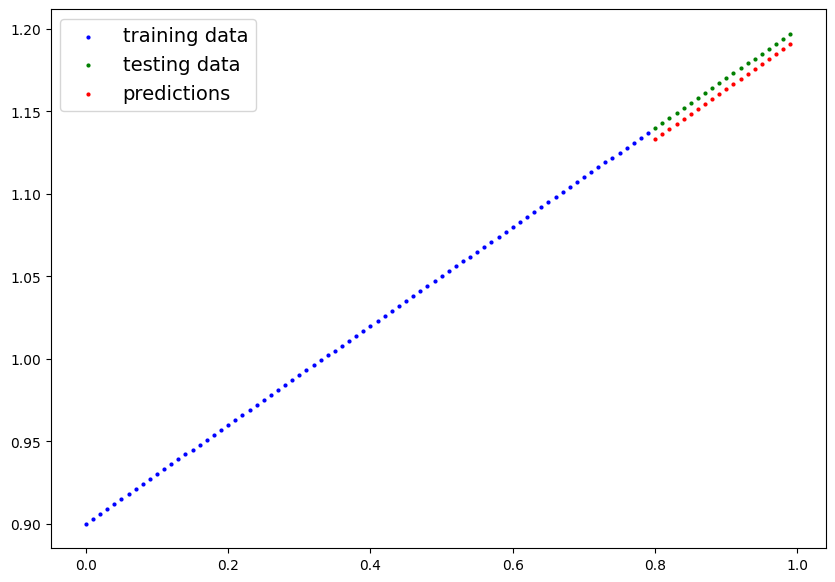

In [91]:
# Make predictions using the trained model
model_1.eval()

with torch.inference_mode():
    y_pred = model_1(X_test)

# Visualize training data, testing data, and predictions
plot_predictions(predictions=y_pred.cpu().numpy())

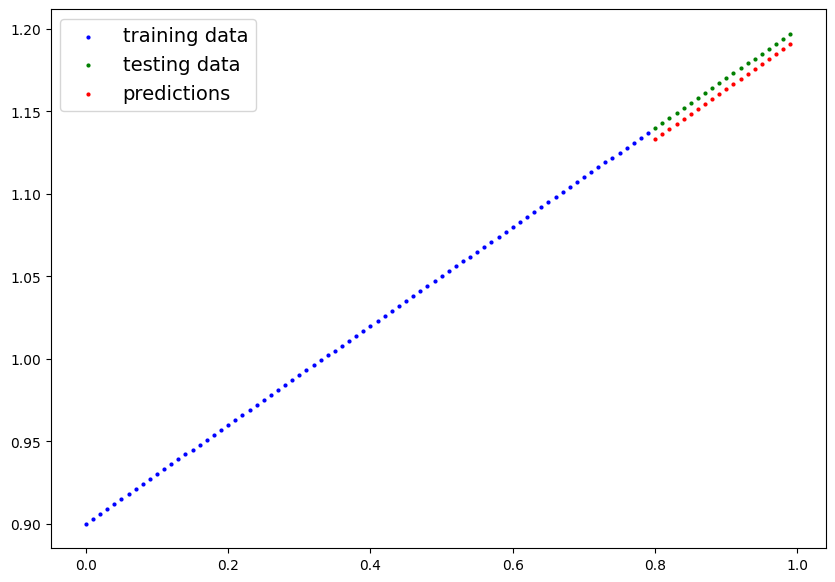

In [92]:
##matplot lib works on numpy so we have to detach it as it still consist the SGD in the training loop so when we detach it can convert tensor to
#the numpy and also we can use .cpu() or .numpy()

plot_predictions(predictions=y_pred.detach())

In [93]:
# Save the trained model parameters
torch.save(model_1.state_dict(), "model_1.pth")

In [94]:
# save the model_0
torch.save(model_0.state_dict(), "model_0.pth")

In [95]:
##new instance for the model, the new model wont have the trained weight and bias we will pass to it now in next code

loaded_model = LinearRegressionModel()
loaded_model.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [99]:
#passing parameters
loaded_model.load_state_dict(torch.load("model_1.pth", weights_only= True))
loaded_model.state_dict()

OrderedDict([('weights', tensor([0.3027])), ('bias', tensor([0.8911]))])

In [101]:
# Load the saved state_dict
loaded_model.load_state_dict(
    torch.load("model_1.pth", weights_only=True)
)

<All keys matched successfully>

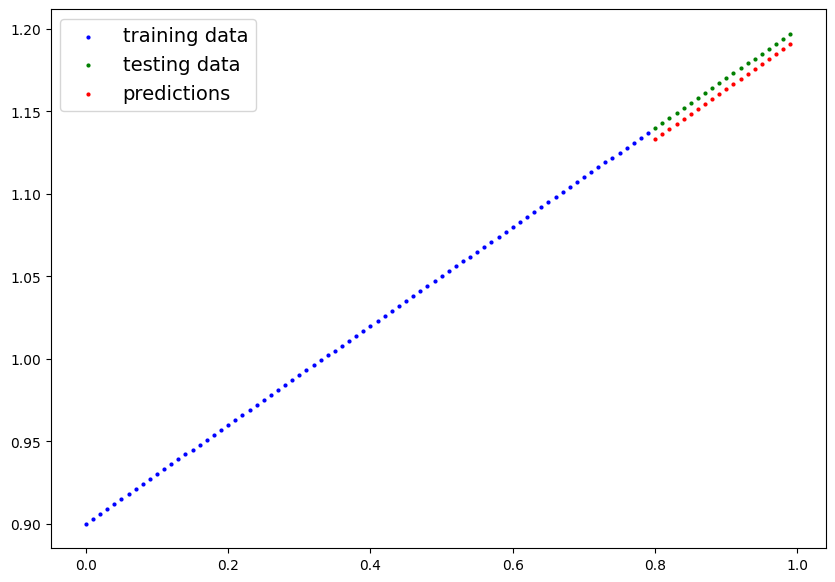

In [103]:
##perform predictions from the loaded model
loaded_model.eval()

with torch.inference_mode():
  y_pred1 = loaded_model(X_test)



In [106]:
model_1.eval()

with torch.inference_mode():
  y_pred2 = model_1(X_test)


In [107]:
torch.allclose(y_pred1, y_pred2)

True